In [1]:
import numpy as np
import matplotlib.pyplot as plt

Note: the file ended up in the homework7 folder of the course_assignments repo instead of homework8, so the path points there. I think hw7 and 8 were switched on course assigments somehow lol

In [2]:
data = np.loadtxt("../../course_assignments/homework7/star_data.txt", skiprows=1)

In [3]:
print(data.shape)
print(f"Rows: {data.shape[0]}, Columns: {data.shape[1]}")

(2642, 2)
Rows: 2642, Columns: 2


The shape is (2642, 2), so there are 2642 rows. Each row is a different star, so I have 2642 stars. The first column is the magnitude and the second column is the temperature in Kelvin.

In [ ]:
# array slicing: all rows first column; all rows second column
magnitude = data[:, 0]
temperature = data[:, 1]

In [5]:
print(f"Min magnitude: {magnitude.min()}")
print(f"Max magnitude: {magnitude.max()}")
print(f"Min temperature: {temperature.min()}")
print(f"Max temperature: {temperature.max()}")

Min magnitude: 2.24
Max magnitude: 12.49
Min temperature: 3653.20966
Max temperature: 10112.78057


In [6]:
# argmin/argmax give the row number, which is how I find the star each value belongs to
brightest = np.argmin(magnitude)
dimmest = np.argmax(magnitude)
hottest = np.argmax(temperature)
coldest = np.argmin(temperature)

for label, i in [("Brightest", brightest), ("Dimmest", dimmest), ("Hottest", hottest), ("Coldest", coldest)]:
    print(f"{label}: row {i}, magnitude {magnitude[i]}, temperature {temperature[i]:.2f} K")

Brightest: row 1988, magnitude 2.24, temperature 3762.19 K
Dimmest: row 264, magnitude 12.49, temperature 4051.20 K
Hottest: row 2613, magnitude 4.59, temperature 10112.78 K
Coldest: row 1923, magnitude 11.02, temperature 3653.21 K


Magnitude is backwards, so the smallest number is the brightest star and the biggest number is the dimmest star.

Brightest star: the one with the lowest magnitude (2.24).
Dimmest star: the one with the highest magnitude (12.49).
Hottest star: the one with the highest temperature (10112.78 K).
Coldest star:  one with the lowest temperature (3653.21 K).

The dataset doesn't have star names

In [7]:
log_magnitude = np.log(magnitude)
log_temperature = np.log(temperature)

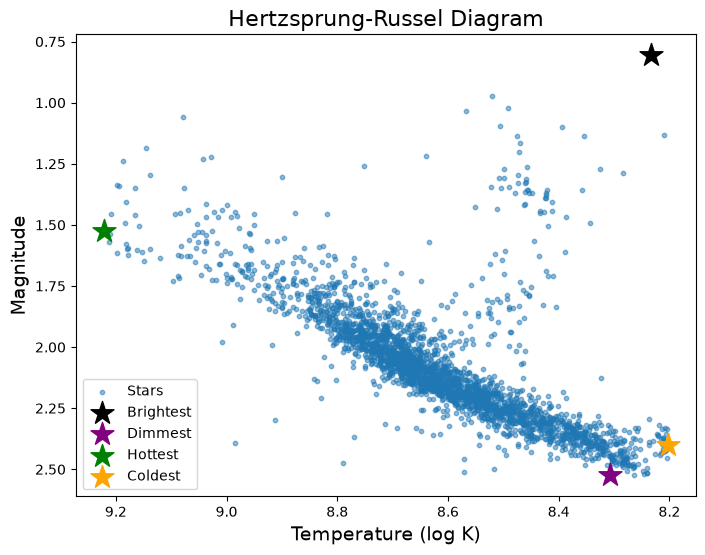

In [8]:
plt.figure(figsize=(8, 6))
plt.scatter(log_temperature, log_magnitude, s=10, color="tab:blue", alpha=0.5, label="Stars")

# plot the four special stars again on top, on the log scale too
plt.scatter(log_temperature[brightest], log_magnitude[brightest], color="black", marker="*", s=300, label="Brightest")
plt.scatter(log_temperature[dimmest], log_magnitude[dimmest], color="purple", marker="*", s=300, label="Dimmest")
plt.scatter(log_temperature[hottest], log_magnitude[hottest], color="green", marker="*", s=300, label="Hottest")
plt.scatter(log_temperature[coldest], log_magnitude[coldest], color="orange", marker="*", s=300, label="Coldest")

# hot stars toward the origin and bright stars toward the origin
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.title("Hertzsprung-Russel Diagram", fontsize=16)
plt.xlabel("Temperature (log K)", fontsize=14)
plt.ylabel("Magnitude", fontsize=14)
plt.legend()
plt.show()

Bonus: the same plot, but with a colormap that goes from the coldest stars to the hottest stars.

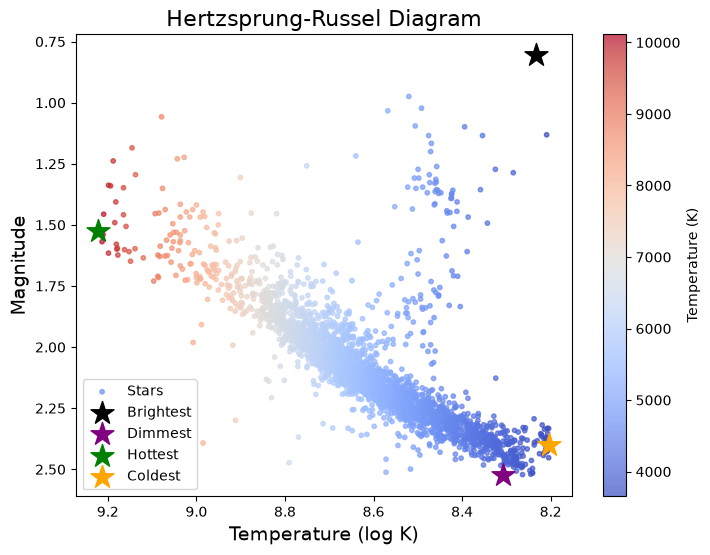

In [9]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(log_temperature, log_magnitude, s=10, c=temperature, cmap="coolwarm", alpha=0.7, label="Stars")

plt.scatter(log_temperature[brightest], log_magnitude[brightest], color="black", marker="*", s=300, label="Brightest")
plt.scatter(log_temperature[dimmest], log_magnitude[dimmest], color="purple", marker="*", s=300, label="Dimmest")
plt.scatter(log_temperature[hottest], log_magnitude[hottest], color="green", marker="*", s=300, label="Hottest")
plt.scatter(log_temperature[coldest], log_magnitude[coldest], color="orange", marker="*", s=300, label="Coldest")

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.colorbar(sc, label="Temperature (K)")
plt.title("Hertzsprung-Russel Diagram", fontsize=16)
plt.xlabel("Temperature (log K)", fontsize=14)
plt.ylabel("Magnitude", fontsize=14)
plt.legend()
plt.show()